# Station sound model: from raw audio to the processed corpus

What this notebook shows, in order: what the raw sources are, what survived into the manifest and why, how the packed corpus differs from the raw files, why all audio is band-limited to 4 kHz,
how the splits are built and checked for leakage, and what the model will actually see (a 40 x 101 log-mel patch). Every number is computed here from `manifests/items.csv` and `data/corpus_v1/corpus.csv`.

In [1]:
import sys, hashlib, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, soundfile as sf, matplotlib.pyplot as plt
from scipy.signal import welch
ROOT = Path("..").resolve(); sys.path.insert(0, str(ROOT / "src")); import features as F
ROOTS = {"patrol": Path("/Users/kireeti/Desktop/Projects/SECURE-FOREST-PATROL/ml/datasets/raw"), "acoustic": ROOT / "data"}
CORPUS = ROOT / "data" / "corpus_v1"
items = pd.read_csv(ROOT / "manifests" / "items.csv", keep_default_na=False)
corpus = pd.read_csv(CORPUS / "corpus.csv", keep_default_na=False)
CLASSES = ["chainsaw", "blast", "fire", "wood", "wind", "background"]; SPLITS = ["train", "val", "test_in", "test_ext"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(len(items), "items in the manifest;", len(corpus), "in the packed corpus")

43715 items in the manifest; 21120 in the packed corpus


## 1. Raw sources
Eight public sources plus our own collections. `licence class`: open = CC0 / CC BY, nc = non-commercial, unknown = per-clip Freesound licences that were not recorded.

In [2]:
ok = items[items.status == "ok"].copy(); ok["dur"] = ok["dur"].astype(float); ok["sr"] = ok["sr"].astype(int)
t = ok.groupby("source").agg(items=("cls", "size"), hours=("dur", lambda s: round(s.sum() / 3600, 2)), classes=("cls", lambda s: ", ".join(sorted(set(s)))),
                             licence=("lic_class", lambda s: "/".join(sorted(set(s)))), rates=("sr", lambda s: "/".join(str(int(v)) for v in sorted(set(s)))))
t.sort_values("hours", ascending=False)

,items,hours,classes,licence,rates
source,,,,,
belize,35631,39.59,"background, blast",open,8000
fsd50k,2728,7.36,"background, blast, fire, wind, wood",nc/open/unknown,44100
freesound_targeted,723,4.42,"chainsaw, fire, wood",open,16000/22050/32000/44100/48000
sensing_forest,35,2.92,background,open,44100
fsc22,1618,2.25,"background, blast, chainsaw, fire, wind, wood",unknown,11025/16000/22050/24000/32000/44100/48000/8820...
esc50,496,0.69,"background, chainsaw, fire, wind",nc,44100
frugalai,400,0.33,"background, chainsaw",nc,12000/24000
rodopi,449,0.30,"background, chainsaw",unknown,8000
freesound_real_fire,3,0.26,fire,nc/open,32000/44100/48000


## 2. What survived: from every listed file to a usable item
Status `dup` = same Freesound upload already kept from a higher-priority source. `conflict` = two sources labelled the same upload differently and no rule could decide (rules in `scripts/10_build_manifest.py`). `unreadable` = zero-length files inside the Belize archive.

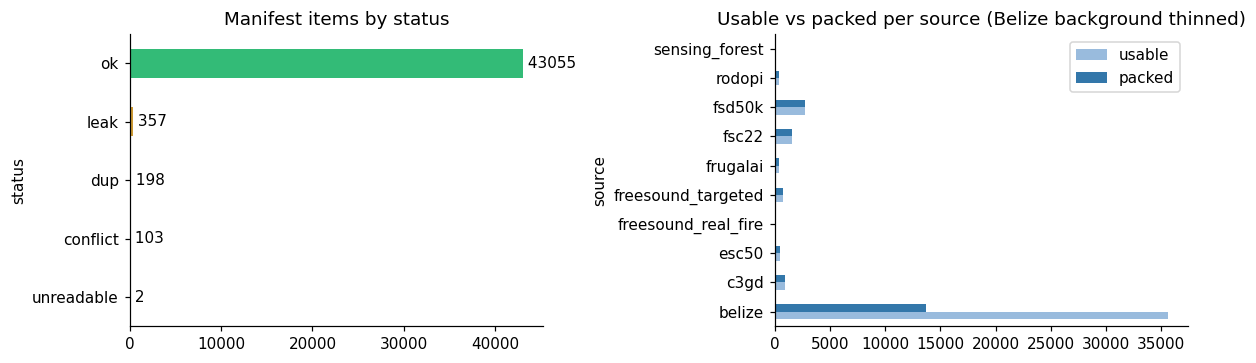

excluded conflicts: 103 | resolved by rule: 22


In [3]:
s = items.status.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
s.plot.barh(ax=ax[0], color=["#3b7", "#c93", "#c55", "#999"][:len(s)]); ax[0].set_title("Manifest items by status"); ax[0].invert_yaxis()
for i, v in enumerate(s.values): ax[0].text(v, i, f" {v}", va="center")
packed = corpus.groupby("source").size(); usable = ok.groupby("source").size()
pd.DataFrame({"usable": usable, "packed": packed}).fillna(0).astype(int).plot.barh(ax=ax[1], color=["#9bd", "#37a"]); ax[1].set_title("Usable vs packed per source (Belize background thinned)")
plt.tight_layout(); plt.savefig(FIG / "funnel.png"); plt.show()
c = items[items.status == "conflict"]; print("excluded conflicts:", len(c), "| resolved by rule:", len(pd.read_csv(ROOT / "manifests" / "label_conflicts.csv")) - len(c))

## 3. Class balance and licences
The point to read: chainsaw and fire are small, background is huge. Training will sample by class and by source, not by raw count.

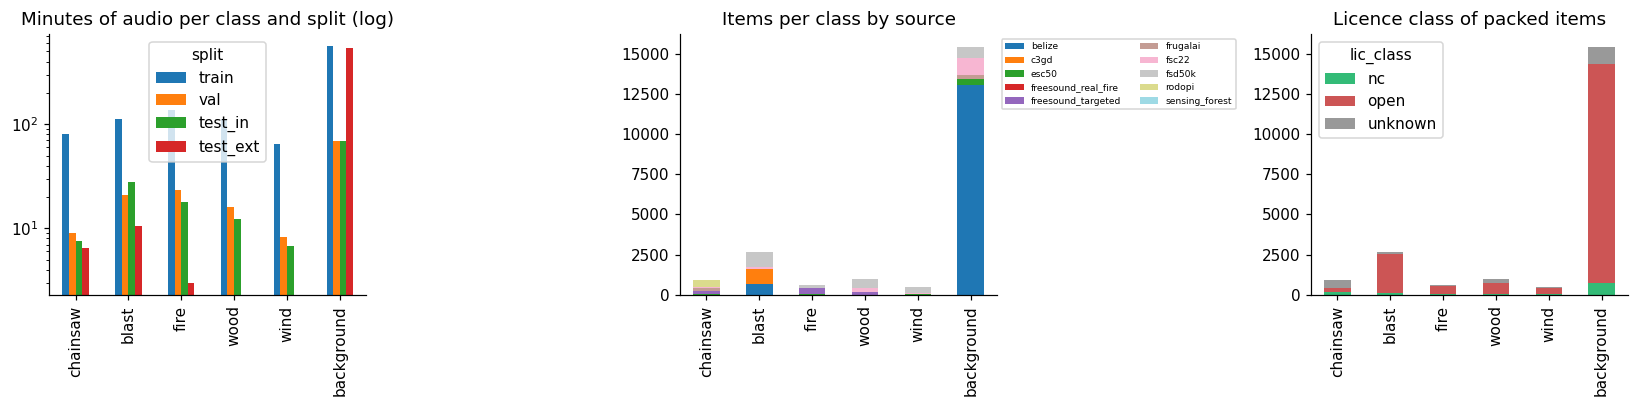

split,train,val,test_in,test_ext
cls,,,,
chainsaw,80.1,9.1,7.6,6.6
blast,112.6,20.9,27.9,10.6
fire,138.6,23.5,18.0,3.0
wood,113.2,15.9,12.3,0.0
wind,64.3,8.3,6.8,0.0
background,564.6,69.2,69.6,539.4


In [4]:
mins = corpus.assign(dur=corpus.dur.astype(float)).pivot_table(index="cls", columns="split", values="dur", aggfunc="sum").reindex(CLASSES)[SPLITS].fillna(0) / 60
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
mins.plot.bar(ax=ax[0], logy=True); ax[0].set_title("Minutes of audio per class and split (log)"); ax[0].set_xlabel("")
pd.crosstab(corpus.cls, corpus.source).reindex(CLASSES).plot.bar(ax=ax[1], stacked=True, legend=False, colormap="tab20"); ax[1].set_title("Items per class by source"); ax[1].set_xlabel("")
ax[1].legend(fontsize=6, ncol=2, bbox_to_anchor=(1.0, 1.0))
pd.crosstab(corpus.cls, corpus.lic_class).reindex(CLASSES).plot.bar(ax=ax[2], stacked=True, color=["#3b7", "#c55", "#999"]); ax[2].set_title("Licence class of packed items"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "class_balance.png"); plt.show(); mins.round(1)

## 4. Raw next to processed
For one item per class: the first seconds of the raw file (native rate, any format) and the packed FLAC (mono, at most 16 kHz). The content must match; only the container and the rate change.

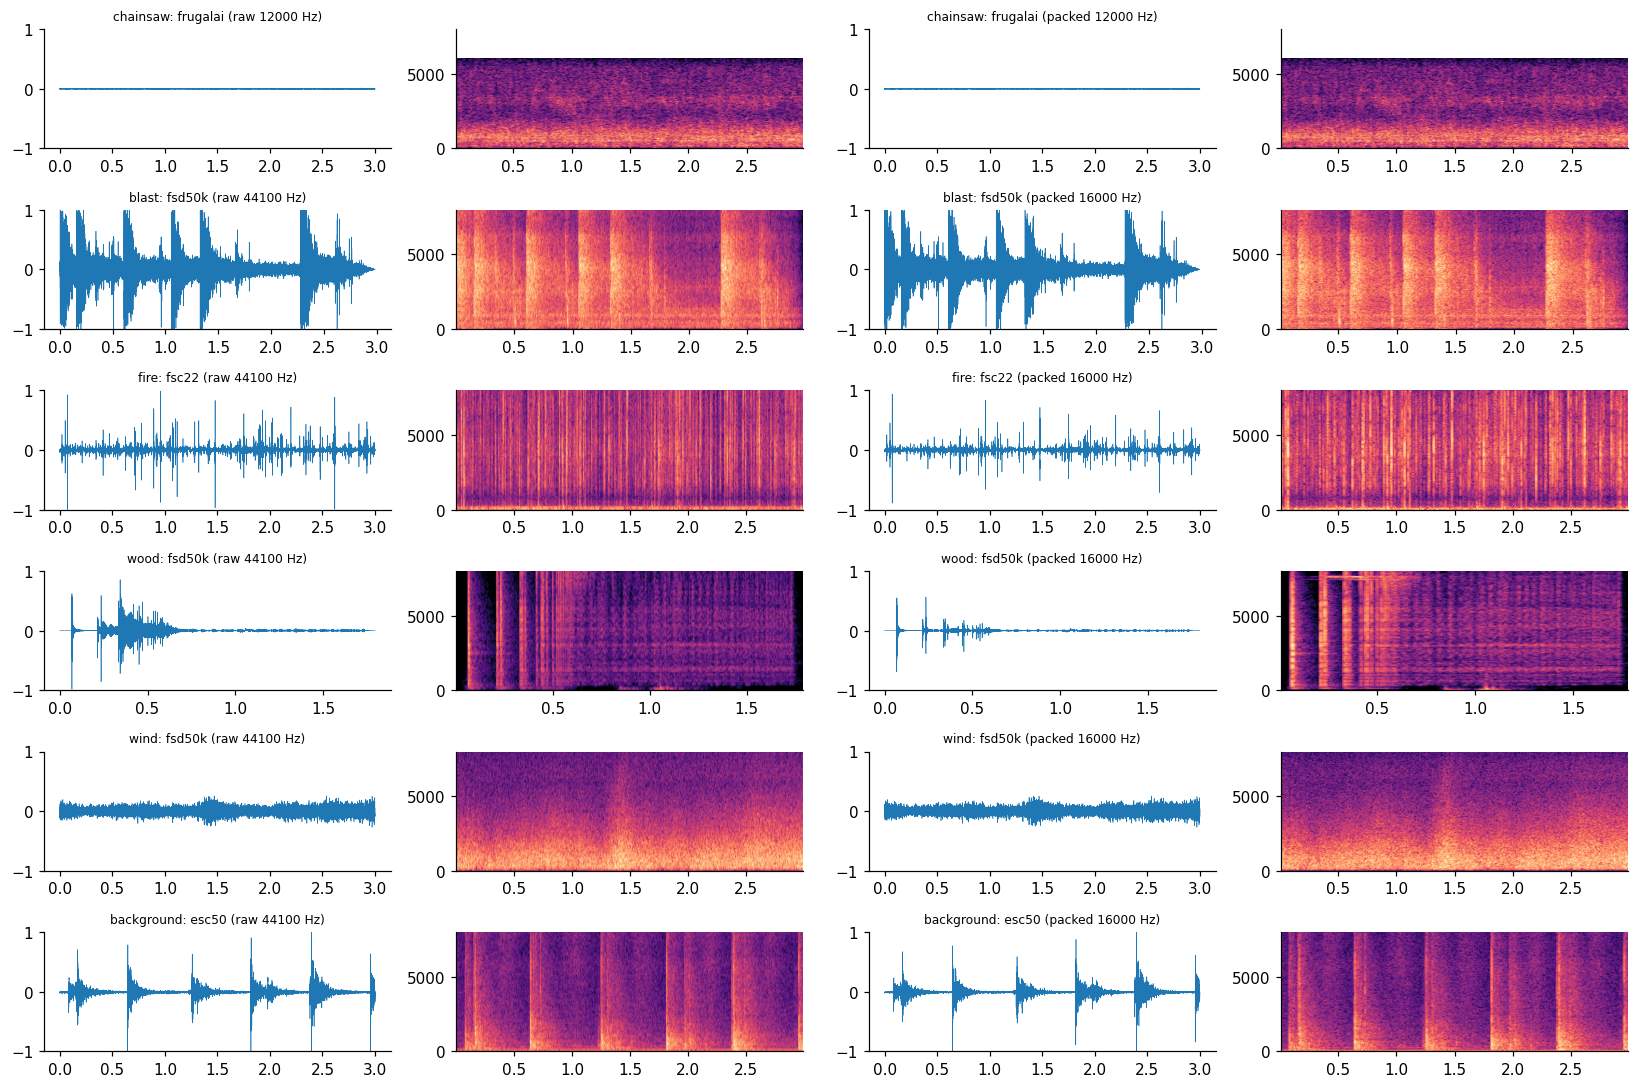

In [5]:
def corpus_id(r): return f"{r.source}_" + hashlib.sha1("|".join((r.root, r.path, str(r.start), str(r.end))).encode()).hexdigest()[:12]
tr = ok[(ok.split == "train")].copy(); tr["id"] = tr.apply(corpus_id, axis=1); cid = dict(zip(corpus.id, corpus.path))
rng = np.random.default_rng(7)
pick = {c: tr[(tr.cls == c) & tr.id.isin(cid)].sample(1, random_state=7).iloc[0] for c in CLASSES}
fig, ax = plt.subplots(len(CLASSES), 4, figsize=(15, 10), gridspec_kw={"width_ratios": [1, 1, 1, 1]})
for row, (c, r) in zip(ax, pick.items()):
    raw, sr0 = sf.read(str(ROOTS[r.root] / r.path), start=int(float(r.start) * sf.info(str(ROOTS[r.root] / r.path)).samplerate), frames=int(3 * sf.info(str(ROOTS[r.root] / r.path)).samplerate), dtype="float32", always_2d=True)
    raw = raw.mean(1); pro, sr1 = sf.read(str(CORPUS / cid[r.id]), frames=3 * 16000, dtype="float32")
    for a, y, sr, name in ((row[0], raw, sr0, f"raw {sr0} Hz"), (row[2], pro, sr1, f"packed {sr1} Hz")):
        a.plot(np.arange(len(y)) / sr, y, lw=0.4); a.set_title(f"{c}: {r.source} ({name})", fontsize=8); a.set_ylim(-1, 1)
    for a, y, sr in ((row[1], raw, sr0), (row[3], pro, sr1)):
        a.specgram(y, Fs=sr, NFFT=512, noverlap=384, cmap="magma", vmin=-120); a.set_ylim(0, 8000)
plt.tight_layout(); plt.savefig(FIG / "raw_vs_processed.png"); plt.show()

## 5. Why everything is band-limited to 4 kHz
Belize (the only forest gunshot source) was recorded at 8 kHz, so its audio stops at 4 kHz; the other gunshot sources reach higher. A model could learn 'nothing above 4 kHz means gunshot'. Resampling every clip to 8 kHz removes that clue.

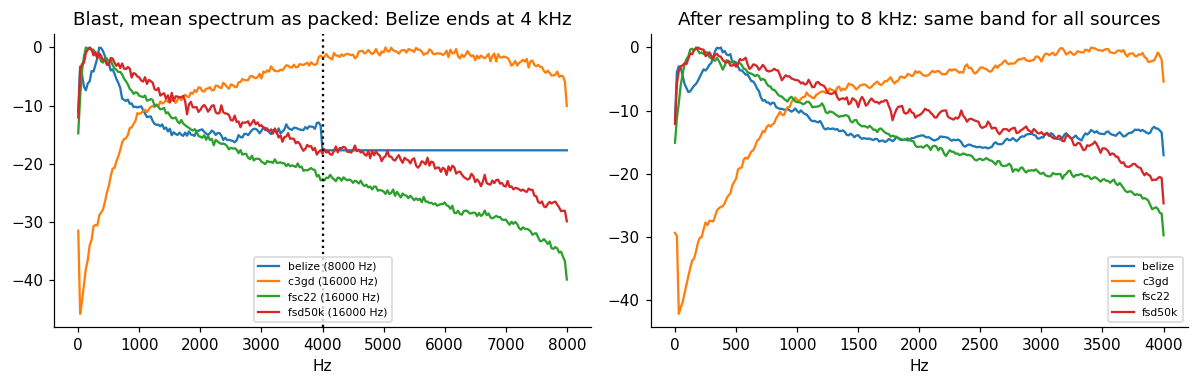

In [6]:
def mean_psd(sub, n=25):
    acc = []
    for r in sub.sample(min(n, len(sub)), random_state=1).itertuples():
        y, sr = sf.read(str(CORPUS / r.path), dtype="float32"); f, p = welch(y, fs=sr, nperseg=1024); acc.append(np.interp(np.linspace(0, 8000, 257), f, 10 * np.log10(p + 1e-14)))
    return np.linspace(0, 8000, 257), np.mean(acc, 0)
blast = corpus[(corpus.cls == "blast") & (corpus.split == "train")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for src, g in blast.groupby("source"):
    f, p = mean_psd(g); ax[0].plot(f, p - p.max(), label=f"{src} ({g.sr.iloc[0]} Hz)")
ax[0].axvline(4000, color="k", ls=":"); ax[0].set_title("Blast, mean spectrum as packed: Belize ends at 4 kHz"); ax[0].set_xlabel("Hz"); ax[0].legend(fontsize=7)
for src, g in blast.groupby("source"):
    ps = []
    for r in g.sample(min(25, len(g)), random_state=1).itertuples():
        y, sr = sf.read(str(CORPUS / r.path), dtype="float32"); y8 = F.to_8k(y, sr); f, p = welch(y8, fs=8000, nperseg=512); ps.append(10 * np.log10(p + 1e-14))
    ax[1].plot(f, np.mean(ps, 0) - np.mean(ps, 0).max(), label=src)
ax[1].set_title("After resampling to 8 kHz: same band for all sources"); ax[1].set_xlabel("Hz"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "bandlimit.png"); plt.show()

## 6. Splits and leakage checks
`test_ext` = whole sources or periods never trained on. The rest is split by a hash of the recording or Freesound upload (`group`), so no group straddles two splits.

In [7]:
g = corpus.groupby("group").split.nunique(); leaks = g[g > 1]
print("groups in more than one split:", len(leaks)); display(leaks.head())
held = corpus[corpus.split == "test_ext"].groupby(["cls", "source"]).size().unstack(fill_value=0); display(held)
pd.crosstab(corpus.source, corpus.split)

groups in more than one split: 0


Series([], Name: split, dtype: int64)

source,belize,c3gd,freesound_real_fire,rodopi,sensing_forest
cls,,,,,
background,7040,0,0,3,35
blast,150,84,0,0,0
chainsaw,0,0,0,154,0
fire,0,0,3,0,0


split,test_ext,test_in,train,val
source,,,,
belize,7190,782,5083,641
c3gd,84,144,528,216
esc50,0,41,417,38
freesound_real_fire,3,0,0,0
freesound_targeted,0,71,572,80
frugalai,0,35,326,39
fsc22,0,161,1277,180
fsd50k,0,258,2194,276
rodopi,157,0,252,40


## 7. Item lengths
Long recordings were capped (60 s, Sensing the Forest 120 s) and cut to their labelled interval. The model sees 1 s windows cut from these.

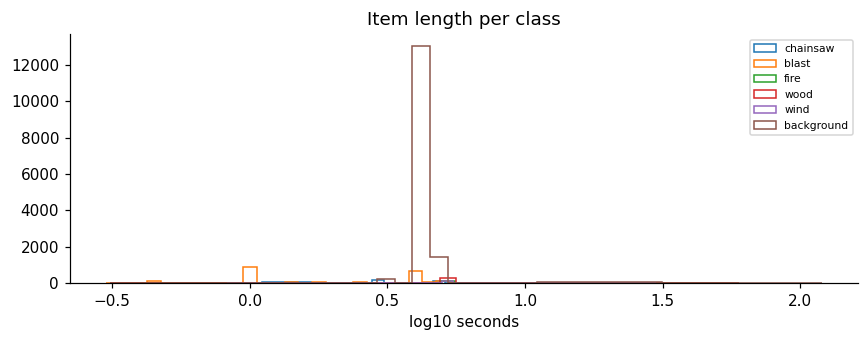

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for c in CLASSES: ax.hist(np.log10(corpus[corpus.cls == c].dur.astype(float).clip(lower=0.1)), bins=40, histtype="step", label=c)
ax.set_xlabel("log10 seconds"); ax.set_title("Item length per class"); ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "lengths.png"); plt.show()

## 8. What the model sees
One 1 s window per class (impulsive sounds aligned so the peak is 250 ms in, like the station's microphone trigger): log-mel, 40 bands, 50 to 4000 Hz, 101 frames, referenced to the patch maximum.

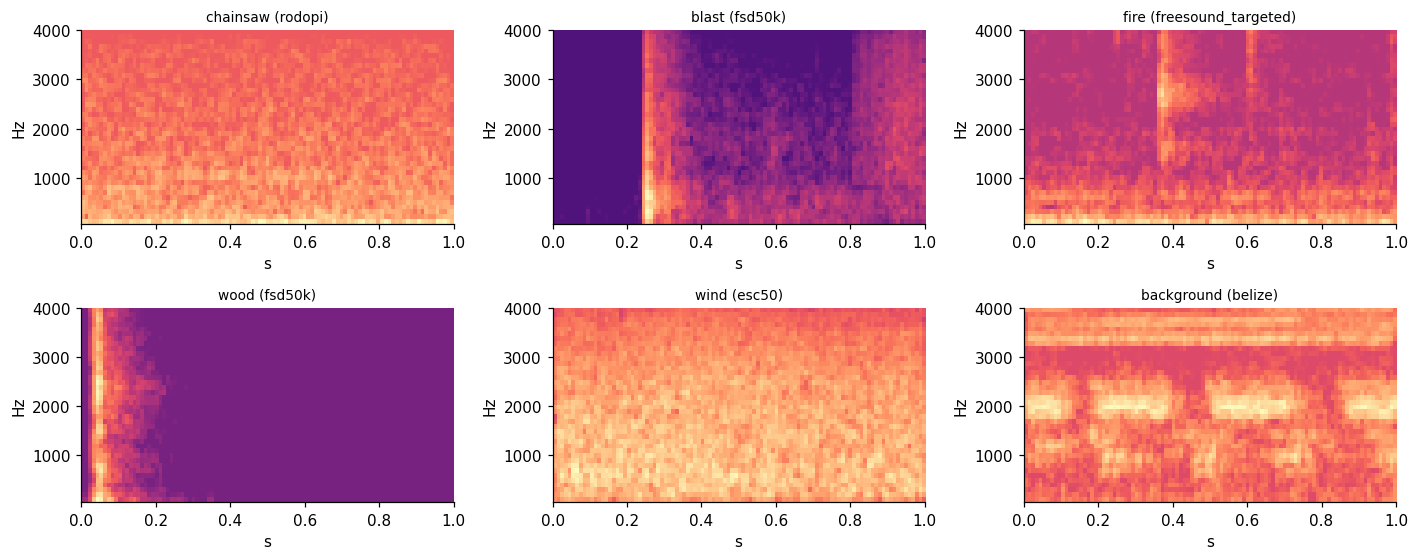

patch shape (40, 101)


In [9]:
fig, ax = plt.subplots(2, 3, figsize=(13, 5.2)); rs = np.random.default_rng(3)
for a, c in zip(ax.ravel(), CLASSES):
    r = corpus[(corpus.cls == c) & (corpus.split == "train")].sample(1, random_state=11).iloc[0]
    y, sr = sf.read(str(CORPUS / r.path), dtype="float32"); w = F.window(F.to_8k(y, sr), r.rule, rs); m = F.logmel(w)
    a.imshow(m, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0, extent=[0, 1, 50, 4000]); a.set_title(f"{c} ({r.source})", fontsize=9); a.set_xlabel("s"); a.set_ylabel("Hz")
plt.tight_layout(); plt.savefig(FIG / "features.png"); plt.show(); print("patch shape", m.shape)

## 9. Checks

In [10]:
checks = {"unique corpus ids": corpus.id.is_unique, "every packed file exists": all((CORPUS / p).exists() for p in corpus.path),
          "no group in two splits": len(leaks) == 0, "held-out items never in train": not set(corpus[corpus.split == "test_ext"].group) & set(corpus[corpus.split == "train"].group),
          "all rates <= 16 kHz": corpus.sr.astype(int).max() <= 16000, "no excluded status packed": True}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())

PASS unique corpus ids
PASS every packed file exists
PASS no group in two splits
PASS held-out items never in train
PASS all rates <= 16 kHz
PASS no excluded status packed
